<a href="https://colab.research.google.com/github/NourEhab21/IT_Procurement_MAS/blob/main/IT_Procurement_MAS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IT Procurement Workflows Multi-Agent System

This notebook implements a multi-agent AI system designed for managing and evaluating IT procurement requests at a university. It is designed to run seamlessly on Google Colab and uses historical datasets to verify inventory, select vendors, perform IT compliance checks, score value-for-money, and manage budget rules.

### **Workflow Overview**
1. **Human opens ticket**: Input an IT procurement request.
2. **Proxy Agent**: Rewrites request clearly, extracts category, quantity, budget, and keywords, and checks `Laptop_Inventory_Database.csv` inventory for exact product match. Returns `FULL` (close ticket), `PARTIAL` (collect available + procure remaining), or `NOT_FOUND` (full procurement).
3. **Orchestrator Agent**: Manages and validates workflow states between agents using structured validation feedback loops.
4. **RFQ Agent**: Queries `Vendor_RFQ_Database.csv` for vendors strictly matching requested brand. Recommends requested brand vendors only and attaches a `⚠️ RISK FLAG` for Human CFO review if specifications are incomplete.
5. **IT Agent**: Queries `laptop.csv` for specs of requested brands and verifies technical specs compliance (RAM, CPU, Storage, Display size).
6. **Finance Agent**: Computes value-for-money scores (0-100 scale) directly from `Vendor_RFQ_Database.csv` on price, delivery, warranty, ratings, and accuracy. Cross-references IT Agent findings, evaluates vendor price against user budget, and appends a `⚠️ BUDGET FLAG` if price exceeds stated budget.
7. **CFO Agent**: Quantity & budget-aware check against user stated budget. Extracts actual numeric vendor prices, accounts for warehouse inventory at $0, evaluates budget strictly for external procurement units, and passes to Human CFO with all flags intact without auto-rejecting.
8. **Human CFO Review**: Reviews full transcript, risk flags, and budget flags, and votes `APPROVE` or `REJECT`.
9. **CEO Agent**: Formulates board recommendations.
10. **Human CEO Review**: Final decision to execute procurement.

## 1. Setup & Installation

In [2]:
# Install official API clients and table rendering library
!pip install -q openai anthropic pandas tabulate openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 25.9 MB/s eta 0:00:00


In [3]:
import os
import re
import time
import json
import getpass
import pandas as pd
from typing import Dict, List, Tuple, Any
from unittest.mock import patch
from openai import OpenAI
from anthropic import Anthropic

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. API Key Entry

In [ ]:
# ==========================================
# 2. AUTOMATIC API KEY LOADER (FROM .MD FILE)
# ==========================================
md_file_path = "api_keys.md"

openai_api_key = None
anthropic_api_key = None

# Check if the .md file exists
if not os.path.exists(md_file_path):
    # Check if it was uploaded to /content/ in Colab
    if os.path.exists(os.path.join('/content', md_file_path)):
        md_file_path = os.path.join('/content', md_file_path)

if os.path.exists(md_file_path):
    print(f" Reading API keys from: {md_file_path}")
    with open(md_file_path, "r", encoding="utf-8") as f:
        content = f.read()

    # Extract OpenAI Key
    m_openai = re.search(r'(?:OPENAI_API_KEY|OPENAI|OPENAI_KEY)\s*[:=]\s*([^\s\r\n]+)', content, re.IGNORECASE)
    if m_openai:
        openai_api_key = m_openai.group(1).strip().strip('"').strip("'")

    # Extract Anthropic Key
    m_anthropic = re.search(r'(?:ANTHROPIC_API_KEY|ANTHROPIC|CLAUDE_KEY)\s*[:=]\s*([^\s\r\n]+)', content, re.IGNORECASE)
    if m_anthropic:
        anthropic_api_key = m_anthropic.group(1).strip().strip('"').strip("'")
else:
    raise FileNotFoundError(f"❌ File '{md_file_path}' not found. Please upload '{md_file_path}' to Colab.")

# Validate that both keys were found
if not openai_api_key or not anthropic_api_key:
    raise ValueError("❌ Could not extract both keys from the .md file. Please check the file formatting.")

# Initialize API clients
openai_client = OpenAI(api_key=openai_api_key)
anthropic_client = Anthropic(api_key=anthropic_api_key)

print("✅ OpenAI client initialized successfully.")
print("✅ Anthropic client initialized successfully.")
print("🚀 No interactive input needed!")

--- Configure API Keys ---
Enter OpenAI API Key: ··········
Enter Anthropic API Key: ··········
Clients initialized successfully.


## 3. Database Location & Verification
Upload your 3 CSV files (`Laptop_Inventory_Database.csv`, `Vendor_RFQ_Database.csv`, `laptop.csv`) to Colab by clicking the folder icon on the left sidebar.

In [ ]:
def locate_file(filename: str) -> str:
    """
    Locates files by checking the current directory, Colab's /content folder,
    or specific allowed subfolders (Inventory, Laptop Dataset, Vendor_RFQ_Database).
    Explicitly avoids scanning VendorSupplier and RFQPurchase Orders.
    """
    target_name = filename
    if filename == "hardwareStore.csv":
        target_name = "Laptop_Inventory_Database.csv"

    if os.path.exists(target_name):
        return target_name
    if os.path.exists(filename):
        return filename

    colab_path = os.path.join('/content', target_name)
    if os.path.exists(colab_path):
        return colab_path

    allowed_dirs = ['Inventory', 'Vendor_RFQ_Database', 'Laptop Dataset']
    for d in allowed_dirs:
        path = os.path.join(d, target_name)
        if os.path.exists(path):
            return path
        path_orig = os.path.join(d, filename)
        if os.path.exists(path_orig):
            return path_orig

        if os.path.exists(d):
            for f in os.listdir(d):
                norm_f = f.lower().replace('_', '').replace(' ', '')
                norm_target = target_name.lower().replace('_', '').replace(' ', '')
                if norm_f == norm_target or norm_f.replace('.csv', '') == norm_target.replace('.csv', ''):
                    return os.path.join(d, f)
            if "inventory" in target_name.lower() or "laptop" in target_name.lower():
                csv_files = [f for f in os.listdir(d) if f.endswith('.csv')]
                if csv_files:
                    return os.path.join(d, csv_files[0])
    return target_name

# Verification test
for db_file in ["Laptop_Inventory_Database.csv", "Vendor_RFQ_Database.csv", "laptop.csv"]:
    resolved = locate_file(db_file)
    status = "✅ FOUND" if os.path.exists(resolved) else "❌ NOT FOUND"
    print(f"{db_file} -> {resolved} : {status}")

Laptop_Inventory_Database.csv -> Laptop_Inventory_Database.csv : ✅ FOUND
Vendor_RFQ_Database.csv -> Vendor_RFQ_Database.csv : ✅ FOUND
laptop.csv -> laptop.csv : ✅ FOUND


## 4. Helper Query Functions & Safe Parser

In [ ]:
def parse_proxy_output(proxy_response: str, request_text: str) -> Tuple[str, str, str, int, int]:
    """
    Safely parses Proxy Agent output for REWRITTEN_REQUEST, CATEGORY, SEARCH_KEYWORDS, QUANTITY, and BUDGET.
    Applies robust regex extraction with fallbacks and comma stripping.
    """
    rewritten_req = request_text
    category = "Laptop"
    search_term = request_text
    quantity = 1
    budget = 5000

    try:
        req_match = re.search(r"REWRITTEN_REQUEST:\s*(.*)", proxy_response, re.IGNORECASE)
        if req_match:
            rewritten_req = req_match.group(1).strip()
    except Exception:
        rewritten_req = request_text

    try:
        cat_match = re.search(r"CATEGORY:\s*(.*)", proxy_response, re.IGNORECASE)
        if cat_match:
            raw_cat = cat_match.group(1).strip()
            category = re.sub(r'[^\w\s]', '', raw_cat).strip()
            if not category: category = "Laptop"
    except Exception:
        category = "Laptop"

    try:
        key_match = re.search(r"SEARCH_KEYWORDS:\s*(.*)", proxy_response, re.IGNORECASE)
        if key_match:
            raw_keys = key_match.group(1).strip()
            search_term = re.sub(r'[^\w\s]', ' ', raw_keys).strip()
            if not search_term: search_term = request_text
    except Exception:
        search_term = re.sub(r'[^\w\s]', ' ', request_text).strip()

    try:
        qty_match = re.search(r"QUANTITY:\s*(\d+)", proxy_response, re.IGNORECASE)
        if qty_match:
            quantity = int(qty_match.group(1).strip())
        else:
            num_match = re.search(r"(\d+)\s*(?:x|units?|laptops?|pcs?|items?)", request_text, re.IGNORECASE)
            if num_match:
                quantity = int(num_match.group(1).strip())
    except Exception:
        quantity = 1

    try:
        quantity = int(quantity)
    except Exception:
        quantity = 1
    if quantity <= 0:
        quantity = 1

    try:
        budget_match = re.search(r"BUDGET:\s*\$?([\d,]+)", proxy_response, re.IGNORECASE)
        if budget_match:
            raw_b = budget_match.group(1).replace(',', '').strip()
            budget = int(raw_b)
        else:
            req_budget = re.search(r"(?:budget|cost)\s*(?:is|=|:|\$)?\s*\$?([\d,]+)", request_text, re.IGNORECASE)
            if req_budget:
                raw_b = req_budget.group(1).replace(',', '').strip()
                budget = int(raw_b)
    except Exception:
        budget = 5000

    try:
        budget = int(budget)
    except Exception:
        budget = 5000
    if budget <= 0:
        budget = 5000

    return rewritten_req, category, search_term, quantity, budget

def query_inventory(
    item_name: str,
    category: str,
    df_inventory: pd.DataFrame,
    requested_qty: Any = 1,
    request_text: str = ""
) -> Tuple[str, str, int, str]:
    """
    Checks Laptop_Inventory_Database.csv for stock using strict BRAND and PRODUCT_NAME matching.
    - First matches BRAND column exactly.
    - Then matches PRODUCT_NAME for specific product type (Gaming vs Business vs Standard).
    - NEVER matches different brands or uses broad keyword fallbacks.
    - If brand or product type does not match -> returns NOT_FOUND immediately.
    """
    try:
        requested_qty = int(requested_qty)
    except Exception:
        requested_qty = 1
    if requested_qty <= 0:
        requested_qty = 1

    clean_cat_input = re.sub(r'[^\w\s]', '', category).strip().lower()
    cat_column = 'CATEGORY_NAME' if 'CATEGORY_NAME' in df_inventory.columns else df_inventory.columns[1]
    inventory_categories = [str(cat).strip().lower() for cat in df_inventory[cat_column].unique()]

    category_exists = any(inv_cat in clean_cat_input or clean_cat_input in inv_cat for inv_cat in inventory_categories)
    if not category_exists:
        available_cats = ", ".join([str(c) for c in df_inventory[cat_column].unique()])
        return "NOT_FOUND", f"Requested category '{category}' does not exist in inventory database (Available categories: {available_cats}).", 0, ""

    brand_col = 'BRAND' if 'BRAND' in df_inventory.columns else df_inventory.columns[2]
    prod_col = 'PRODUCT_NAME' if 'PRODUCT_NAME' in df_inventory.columns else df_inventory.columns[3]
    qty_col = 'QUANTITY' if 'QUANTITY' in df_inventory.columns else 'QUANTITY'
    wh_col = 'WAREHOUSE_NAME' if 'WAREHOUSE_NAME' in df_inventory.columns else 'WAREHOUSE_NAME'

    df_inventory_copy = df_inventory.copy()
    df_inventory_copy[qty_col] = pd.to_numeric(df_inventory_copy[qty_col], errors='coerce').fillna(0).astype(int)

    in_stock = df_inventory_copy[df_inventory_copy[qty_col] > 0].copy()
    if in_stock.empty:
        return "NOT_FOUND", "Item is out of stock in existing inventory database.", 0, ""

    search_text = f"{item_name} {request_text}".lower()

    # 1. STRICT BRAND MATCH: Extract requested brand and match BRAND column exactly
    known_brands = ['dell', 'hp', 'lenovo', 'apple', 'acer', 'asus', 'msi', 'infinix', 'tecno', 'microsoft']
    requested_brand = ""
    for b in known_brands:
        if re.search(r'\b' + re.escape(b) + r'\b', search_text):
            requested_brand = b
            break

    if requested_brand:
        brand_stock = in_stock[in_stock[brand_col].astype(str).str.lower() == requested_brand]
        if brand_stock.empty:
            return "NOT_FOUND", f"No inventory stock found for requested brand '{requested_brand.upper()}'.", 0, ""
    else:
        brand_stock = in_stock

    # 2. STRICT PRODUCT TYPE MATCH: Check PRODUCT_NAME for product type qualifiers (Gaming vs Business vs Standard)
    product_types = {'gaming', 'business', 'workstation', 'chromebook', 'macbook', 'air', 'pro', 'studio', 'slim', 'touch', 'convertible'}
    requested_types = {pt for pt in product_types if re.search(r'\b' + pt + r'\b', search_text)}

    if requested_types:
        matched_rows = brand_stock[brand_stock[prod_col].astype(str).str.lower().apply(lambda name: all(pt in name for pt in requested_types))]
    else:
        # Standard product request (e.g. "HP Laptop") -> exclude specialized types like 'business' or 'gaming'
        candidate_types = {'gaming', 'business', 'workstation', 'chromebook', 'macbook', 'pro', 'studio', 'slim', 'touch'}
        matched_rows = brand_stock[~brand_stock[prod_col].astype(str).str.lower().apply(lambda name: any(pt in name for pt in candidate_types))]
        if matched_rows.empty:
            matched_rows = brand_stock

    if matched_rows.empty:
        return "NOT_FOUND", f"No exact product type matched your request in inventory for brand '{requested_brand.upper()}'.", 0, ""

    # Select exact matched product name and calculate stock
    first_product_name = matched_rows[prod_col].iloc[0]
    product_group = matched_rows[matched_rows[prod_col] == first_product_name]
    available_qty = int(product_group[qty_col].sum())

    details = []
    for _, row in product_group.iterrows():
        details.append(f"- {row[prod_col]} ({row[wh_col]}): {int(row[qty_col])} unit(s)")
    details_str = "\n".join(details)

    if available_qty >= requested_qty:
        status = "FULL"
        msg = f"FULL stock available! Found {available_qty} unit(s) of '{first_product_name}' in inventory (Requested: {requested_qty}).\nLocations:\n{details_str}"
    elif available_qty > 0:
        status = "PARTIAL"
        msg = f"PARTIAL stock available! Found {available_qty} unit(s) of '{first_product_name}' in inventory (Requested: {requested_qty}).\nCollect {available_qty} unit(s) from warehouse; remaining {requested_qty - available_qty} unit(s) passed to Orchestrator for procurement.\nLocations:\n{details_str}"
    else:
        status = "NOT_FOUND"
        msg = f"Product '{first_product_name}' was found in catalog but is currently out of stock."

    return status, msg, available_qty, str(first_product_name)

def query_vendors(item_category: str, df_rfq: pd.DataFrame, requested_brand: str = "") -> Tuple[str, bool, bool]:
    """
    Finds vendors from Vendor_RFQ_Database.csv.
    Filters strictly for requested_brand if specified and found in DB.
    Returns (table_markdown, has_incomplete_specs, brand_found).
    """
    clean_cat = re.sub(r'[^\w\s]', '', item_category).strip().lower()
    clean_brand = re.sub(r'[^\w\s]', '', requested_brand).strip().lower() if requested_brand else ""

    category_matches = df_rfq[df_rfq['Item_Category'].astype(str).str.lower().str.contains(clean_cat, regex=False, na=False)].copy()
    if category_matches.empty:
        category_matches = df_rfq[df_rfq['Item_Name'].astype(str).str.lower().str.contains(clean_cat, regex=False, na=False)].copy()

    if category_matches.empty:
        category_matches = df_rfq.copy()

    brand_found = False
    if clean_brand:
        brand_matches = category_matches[
            category_matches['Item_Name'].astype(str).str.lower().str.contains(clean_brand, regex=False, na=False) |
            category_matches['Vendor_Name'].astype(str).str.lower().str.contains(clean_brand, regex=False, na=False)
        ]
        if not brand_matches.empty:
            category_matches = brand_matches
            brand_found = True

    cols = ['Vendor_Name', 'Item_Name', 'Unit_Price_USD', 'Delivery_Days', 'Warranty_Years', 'Vendor_Rating', 'Order_Accuracy_Pct']
    existing_cols = [c for c in cols if c in df_rfq.columns]

    result_table = category_matches[existing_cols].to_markdown(index=False)

    has_incomplete_specs = True

    filter_note = ""
    if clean_brand and brand_found:
        filter_note = f"\n\n[DATABASE FILTER: Displaying ONLY vendors for requested brand '{requested_brand.upper()}'.]"
    elif clean_brand and not brand_found:
        filter_note = f"\n\n[DATABASE FILTER: Requested brand '{requested_brand.upper()}' has no direct vendor bids in DB. Displaying all available category vendors.]"
    return result_table + filter_note, has_incomplete_specs, brand_found

def query_laptop_specs(brand: str, df_laptop: pd.DataFrame) -> str:
    clean_brand = re.sub(r'[^\w\s]', '', brand).strip().lower()
    matches = df_laptop[df_laptop['Brand'].astype(str).str.lower() == clean_brand]
    if matches.empty:
        matches = df_laptop[df_laptop['Name'].astype(str).str.lower().str.contains(clean_brand, regex=False, na=False)]
    if matches.empty:
        return f"No specs matched brand: '{brand}'."

    matches_sorted = matches.sort_values(by='Price')
    step = max(1, len(matches_sorted) // 8)
    subset = matches_sorted.iloc[::step].head(8)
    cols = ['Brand', 'Name', 'Price', 'Processor_Name', 'RAM', 'SSD', 'Display']
    existing_cols = [c for c in cols if c in df_laptop.columns]
    return subset[existing_cols].to_markdown(index=False)

def calculate_finance_scores(df_rfq: pd.DataFrame, category: str = "Laptop") -> str:
    clean_cat = re.sub(r'[^\w\s]', '', category).strip().lower()
    matches = df_rfq[df_rfq['Item_Category'].astype(str).str.lower() == clean_cat].copy()
    if matches.empty:
        matches = df_rfq[df_rfq['Item_Name'].astype(str).str.lower().str.contains(clean_cat, regex=False, na=False)].copy()

    if matches.empty:
        return "No vendors matched category/name in Vendor_RFQ_Database.csv to score."

    min_price = matches['Unit_Price_USD'].min()
    min_delivery = matches['Delivery_Days'].min()
    max_warranty = matches['Warranty_Years'].max()

    scores = []
    for _, row in matches.iterrows():
        price = row['Unit_Price_USD']
        delivery = row['Delivery_Days']
        warranty = row['Warranty_Years']
        rating = row['Vendor_Rating']
        accuracy = row['Order_Accuracy_Pct']

        p_score = 20 * (min_price / price) if price > 0 else 0
        d_score = 20 * (min_delivery / delivery) if delivery > 0 else 0
        w_score = 20 * (warranty / max_warranty) if max_warranty > 0 else 0
        r_score = 20 * (rating / 5.0)
        a_score = 20 * (accuracy / 100.0)

        total_score = round(p_score + d_score + w_score + r_score + a_score, 2)

        scores.append({
            'Vendor_Name': row['Vendor_Name'],
            'Item_Name': row['Item_Name'],
            'Unit_Price_USD': price,
            'Delivery_Days': delivery,
            'Warranty_Years': warranty,
            'Vendor_Rating': rating,
            'Order_Accuracy_Pct': accuracy,
            'Price_Score': round(p_score, 1),
            'Delivery_Score': round(d_score, 1),
            'Warranty_Score': round(w_score, 1),
            'Rating_Score': round(r_score, 1),
            'Accuracy_Score': round(a_score, 1),
            'Total_Score': total_score
        })

    df_scores = pd.DataFrame(scores)
    df_scores = df_scores.sort_values(by='Total_Score', ascending=False)
    return df_scores.to_markdown(index=False)

## 5. Version 1: Anthropic Claude Implementation (`claude-sonnet-4-6`)

In [ ]:
def run_workflow_claude(
    request_text: str,
    df_inventory: pd.DataFrame,
    df_rfq: pd.DataFrame,
    df_laptop: pd.DataFrame,
    client,
    model_name: str = "claude-sonnet-4-6",
    cfo_input: str = None,
    ceo_input: str = None
) -> Tuple[List[Dict[str, str]], str]:

    history = []

    def call_agent(system: str, user: str) -> str:
        message = client.messages.create(
            model=model_name,
            max_tokens=2000,
            system=system,
            messages=[{"role": "user", "content": user}]
        )
        return message.content[0].text

    # STEP 1 - Human Opens Ticket
    print("\n--- STEP 1: HUMAN OPENS TICKET ---")
    print(f"Request: {request_text}")
    history.append({"role": "Human", "agent": "Human", "content": request_text})

    # STEP 2 - Proxy Agent
    print("\n--- STEP 2: PROXY AGENT ACTIVATED ---")
    proxy_system = (
        "You are the Proxy Agent. Read the human's IT procurement request and output a short, simple summary.\n"
        "DO NOT use markdown formatting, tables, bold headers, bullet points, or emojis.\n"
        "Your output MUST strictly follow this exact 5-line format:\n\n"
        "REWRITTEN_REQUEST: <short 1-line clear description of requested item and specs>\n"
        "CATEGORY: <item category e.g. Laptop>\n"
        "SEARCH_KEYWORDS: <space separated keywords with letters and numbers only>\n"
        "QUANTITY: <integer quantity requested>\n"
        "BUDGET: <integer budget in USD extracted from user request, e.g. 1000. If no budget mentioned, output 5000>"
    )
    proxy_response = call_agent(proxy_system, request_text)
    print(f"Proxy Output:\n{proxy_response}")
    history.append({"role": "Proxy Agent", "agent": "Proxy Agent", "content": proxy_response})

    rewritten_req, category, search_term, quantity, stated_budget = parse_proxy_output(proxy_response, request_text)

    inv_status, inv_msg, available_qty, matched_product = query_inventory(search_term, category, df_inventory, quantity, request_text)
    print(f"Inventory Search Results [{inv_status}]:\n{inv_msg}")

    if inv_status == "FULL":
        close_msg = f"TICKET CLOSED: All {quantity} unit(s) of '{matched_product}' exist in stock. Please proceed to warehouse."
        print(close_msg)
        history.append({"role": "Proxy Agent", "agent": "Proxy Agent", "content": close_msg})
        return history, "CLOSED"
    elif inv_status == "PARTIAL":
        needed_qty = quantity - available_qty
        partial_msg = f"PARTIAL INVENTORY: {available_qty} unit(s) of '{matched_product}' available in warehouse. Routing remaining {needed_qty} unit(s) to Orchestrator Agent for procurement."
        print(partial_msg)
        history.append({"role": "Proxy Agent", "agent": "Proxy Agent", "content": partial_msg})
        current_request = f"{rewritten_req} (Quantity Required: {needed_qty} units, User Budget: ${stated_budget})"
    else:
        notFound_msg = f"NOT IN INVENTORY: Item not available in stock. Passing full request for {quantity} unit(s) to Orchestrator Agent."
        print(notFound_msg)
        history.append({"role": "Proxy Agent", "agent": "Proxy Agent", "content": notFound_msg})
        current_request = f"{rewritten_req} (Quantity Required: {quantity} units, User Budget: ${stated_budget})"
    rfq_output = ""
    it_output = ""
    finance_output = ""

    # STEP 3/4/5 - RFQ Agents
    orchestrator_system = (
        "You are the Orchestrator Agent. Route and validate agent reports.\n"
        "Always respond ONLY with a JSON object: {\"valid\": true/false, \"feedback\": \"description\"}"
    )

    rfq_valid = False
    rfq_feedback = "Fetch top vendors matching requested brand from Vendor_RFQ_Database.csv."

    text_to_scan = f"{request_text} {current_request}".lower()
    known_brands = ['dell', 'hp', 'lenovo', 'apple', 'acer', 'asus', 'msi', 'infinix', 'tecno', 'microsoft']
    detected_brand = ""
    for b in known_brands:
        try:
            if re.search(r'\b' + re.escape(b) + r'\b', text_to_scan):
                detected_brand = b
                break
        except Exception:
            if b in text_to_scan:
                detected_brand = b
                break

    rfq_db_context, has_incomplete_specs, brand_found = query_vendors(category, df_rfq, detected_brand)

    for i in range(2):
        rfq_system = (
            "You are the RFQ Agent. Search Vendor_RFQ_Database.csv and select vendor bids.\n"
            "CRITICAL BRAND FILTERING RULES:\n"
            "1. STRICT BRAND FILTERING: You MUST filter strictly by the REQUESTED BRAND in user request.\n"
            "2. NEVER recommend a different brand (like Apple or Dell) as primary option when requested brand (like Lenovo or HP) exists in database.\n"
            "3. Only show alternative brands if requested brand has absolutely ZERO vendors in database.\n"
            "4. If requested brand vendor has incomplete/missing detailed specifications (RAM/SSD/CPU), you MUST append this exact risk flag to output:\n"
            f"⚠️ RISK FLAG: {detected_brand.upper() if detected_brand else 'Requested'} vendor found but specifications are incomplete. Human CFO review required.\n\n"
            f"Database context:\n\n{rfq_db_context}\n"
        )
        rfq_output = call_agent(rfq_system, f"Feedback: {rfq_feedback}")

        if brand_found and "⚠️ RISK FLAG" not in rfq_output:
            rfq_output += f"\n\n⚠️ RISK FLAG: {detected_brand.upper()} vendor found but specifications are incomplete. Human CFO review required."

        print(f"RFQ Output (Attempt {i+1}):\n{rfq_output}")
        history.append({"role": "RFQ Agent", "agent": "RFQ Agent", "content": rfq_output})

        val_res = call_agent(orchestrator_system, f"Validate RFQ output:\n{rfq_output}")
        print(f"Orchestrator Validation: {val_res}")
        try:
            val_json = json.loads(re.sub(r"```json|```", "", val_res).strip())
            rfq_valid = val_json.get("valid", False)
            rfq_feedback = val_json.get("feedback", "")
        except:
            rfq_valid = True
        if rfq_valid: break

    # STEP 6/7 - IT Agent Verification
    print("\n--- STEP 6/7: IT AGENT TECHNICAL REVIEW & ORCHESTRATOR ---")
    it_valid = False
    it_feedback = "Verify if candidate laptops meet specifications (RAM, SSD, screen size)."

    requested_brands = [detected_brand] if detected_brand else ['dell', 'hp', 'lenovo']
    specs_sheet = ""
    for brand in requested_brands:
        specs_sheet += query_laptop_specs(brand, df_laptop) + "\n\n"

    for i in range(2):
        it_system = f"You are the IT Agent. Match proposed RFQ models against database specs for {', '.join(requested_brands)}:\n{specs_sheet}"
        it_output = call_agent(it_system, f"RFQ models: {rfq_output}. Required spec: {rewritten_req}. Feedback: {it_feedback}")
        print(f"IT Output (Attempt {i+1}):\n{it_output}")
        history.append({"role": "IT Agent", "agent": "IT Agent", "content": it_output})

        val_res = call_agent(orchestrator_system, f"Validate IT output:\n{it_output}")
        print(f"Orchestrator Validation: {val_res}")
        try:
            val_json = json.loads(re.sub(r"```json|```", "", val_res).strip())
            it_valid = val_json.get("valid", False)
            it_feedback = val_json.get("feedback", "")
        except:
            it_valid = True
        if it_valid: break
    # STEP 8/9 - Finance scoring
    print("\n--- STEP 8/9: FINANCE AGENT SCORING & ORCHESTRATOR ---")
    fin_valid = False
    fin_feedback = "Score vendors 0-100 and choose the best one."
    score_sheet = calculate_finance_scores(df_rfq, category)

    for i in range(2):
        fin_system = (
            "You are the Finance Agent. Score candidates 0-100 and select the single best vendor.\n"
            "CRITICAL FINANCE & BUDGET RULES:\n"
            "1. IT AGENT CROSS-REFERENCING: Read IT Agent technical review. Reference IT Agent flags before scoring. If IT Agent flagged specification issues, reduce vendor score or add risk flag. Never approve vendor without acknowledging IT Agent findings.\n"
            f"2. USER STATED BUDGET ({stated_budget} USD): Compare recommended vendor total price against user stated budget of ${stated_budget}.\n"
            "   - If vendor total price is WITHIN budget ($ <= stated budget) -> proceed normally.\n"
            "   - If vendor total price EXCEEDS stated budget ($ > stated budget) -> you MUST append this exact flag:\n"
            f"     ⚠️ BUDGET FLAG: Vendor price $PRICE exceeds stated budget of ${stated_budget}. Human CFO review required.\n"
            "   - NEVER automatically reject a vendor due to budget -> always pass to Human CFO with budget flag visible.\n\n"
            f"Vendor scoresheet:\n\n{score_sheet}\n\n"
            "Select highest scoring vendor matching requested brand and explain why."
        )
        fin_output = call_agent(fin_system, f"RFQ: {rfq_output}. IT specs: {it_output}. User Stated Budget: ${stated_budget}. Feedback: {fin_feedback}")
        print(f"Finance Output (Attempt {i+1}):\n{fin_output}")
        history.append({"role": "Finance Agent", "agent": "Finance Agent", "content": fin_output})

        val_res = call_agent(orchestrator_system, f"Validate Finance output:\n{fin_output}")
        print(f"Orchestrator Validation: {val_res}")
        try:
            val_json = json.loads(re.sub(r"```json|```", "", val_res).strip())
            fin_valid = val_json.get("valid", False)
            fin_feedback = val_json.get("feedback", "")
        except:
            fin_valid = True
        if fin_valid: break

    # STEP 10 - CFO Agent budget validation (BUDGET & QUANTITY AWARE)
    print("\n--- STEP 10: CFO BUDGET AGENT ---")
    procurement_units = quantity - available_qty if inv_status == "PARTIAL" else (0 if inv_status == "FULL" else quantity)
    warehouse_units = available_qty if inv_status in ["FULL", "PARTIAL"] else 0

    cfo_system = (
        "You are the CFO Agent in an automated IT procurement system.\n"
        "YOUR SOLE JOB is to perform an automatic budget check against the user's stated budget.\n"
        "CRITICAL INSTRUCTIONS:\n"
        f"1. BUDGET & PRICE AWARENESS: Read the user stated budget (${stated_budget}) and actual vendor price from Finance Agent output. Extract exact numeric prices. NEVER use placeholders like $X or $Y.\n"
        f"2. BUDGET FLAGS: Compare vendor total price against user stated budget of ${stated_budget}. If vendor price exceeds ${stated_budget}, or if a BUDGET FLAG or RISK FLAG exists in previous agent outputs, acknowledge it clearly.\n"
        "3. NO AUTOMATIC REJECTION: Never automatically reject a request. Always pass the evaluation to Human CFO with flags visible.\n"
        f"4. SINGLE ACTUAL QUANTITY ONLY: Only calculate budget for the actual quantity being procured ({procurement_units} unit(s)). DO NOT calculate or show scenarios for other quantities (e.g. 2 units, 5 units).\n"
        f"5. State clearly: '{warehouse_units} unit(s) from warehouse at $0, {procurement_units} unit(s) from vendor at $PRICE each (Total external cost: $TOTAL)'\n"
        f"6. Compare Total External Cost against stated budget of ${stated_budget} and state whether it is within budget or exceeds budget."
    )
    cfo_prompt = (
        f"User Stated Budget: ${stated_budget}\n"
        f"Inventory Breakdown: {warehouse_units} unit(s) in warehouse inventory ($0), {procurement_units} unit(s) required for external procurement.\n"
        f"Finance Report:\n{fin_output}\n\n"
        f"RFQ Bids Context:\n{rfq_output}"
    )
    cfo_output = call_agent(cfo_system, cfo_prompt)
    print(f"CFO Agent Output:\n{cfo_output}")
    history.append({"role": "CFO Agent", "agent": "CFO Agent", "content": cfo_output})

    # STEP 11 - Human CFO Review
    print("\n========================================================")
    print("STEP 11 - HUMAN CFO CONVERSATION HISTORY REVIEW")
    print("========================================================")
    for record in history:
        print(f"[{record['role']}]: {record['content']}")
        print("-"*40)

    human_cfo = str(cfo_input).strip().upper() if cfo_input is not None else "APPROVE"
    print(f"Human CFO Decision: {human_cfo}")
    history.append({"role": "Human CFO", "agent": "Human CFO", "content": human_cfo})
    if human_cfo != "APPROVE":
        return history, "REJECTED BY CFO"

    # STEP 12 - CEO Agent Review
    print("\n--- STEP 12: CEO AUTOMATED REVIEW ---")
    ceo_system = "You are the CEO Agent. Complete a final review of the purchase request and output formal board recommendation."
    ceo_output = call_agent(ceo_system, str(history))
    print(f"CEO Agent Recommendation:\n{ceo_output}")
    history.append({"role": "CEO Agent", "agent": "CEO Agent", "content": ceo_output})

    # STEP 13 - Human CEO Final Approval
    print("\n========================================================")
    print("STEP 13 - HUMAN CEO FINAL AUDIT")
    print("========================================================")
    print(f"CEO recommendation report:\n{ceo_output}")
    human_ceo = str(ceo_input).strip().upper() if ceo_input is not None else "APPROVE"
    print(f"Human CEO Final Decision: {human_ceo}")
    history.append({"role": "Human CEO", "agent": "Human CEO", "content": human_ceo})

    result = "SUCCESSFULLY APPROVED" if human_ceo == "APPROVE" else "FINAL REJECTION"
    print(f"Final Outcome: {result}")
    return history, result

## 6. Version 2: OpenAI GPT-4o Implementation

In [ ]:
def run_workflow_openai(
    request_text: str,
    df_inventory: pd.DataFrame,
    df_rfq: pd.DataFrame,
    df_laptop: pd.DataFrame,
    client,
    model_name: str = "gpt-4o",
    cfo_input: str = None,
    ceo_input: str = None
) -> Tuple[List[Dict[str, str]], str]:

    history = []

    def call_agent(system: str, user: str) -> str:
        response = client.chat.completions.create(
            model=model_name,
            messages=[
                {"role": "system", "content": system},
                {"role": "user", "content": user}
            ],
            temperature=0.2
        )
        return response.choices[0].message.content

    # STEP 1 - Human Opens Ticket
    print("\n--- STEP 1: HUMAN OPENS TICKET ---")
    print(f"Request: {request_text}")
    history.append({"role": "Human", "agent": "Human", "content": request_text})

    # STEP 2 - Proxy Agent
    print("\n--- STEP 2: PROXY AGENT ACTIVATED ---")
    proxy_system = (
        "You are the Proxy Agent. Read the human's IT procurement request and output a short, simple summary.\n"
        "DO NOT use markdown formatting, tables, bold headers, bullet points, or emojis.\n"
        "Your output MUST strictly follow this exact 5-line format:\n\n"
        "REWRITTEN_REQUEST: <short 1-line clear description of requested item and specs>\n"
        "CATEGORY: <item category e.g. Laptop>\n"
        "SEARCH_KEYWORDS: <space separated keywords with letters and numbers only>\n"
        "QUANTITY: <integer quantity requested>\n"
        "BUDGET: <integer budget in USD extracted from user request, e.g. 1000. If no budget mentioned, output 5000>"
    )
    proxy_response = call_agent(proxy_system, request_text)
    print(f"Proxy Output:\n{proxy_response}")
    history.append({"role": "Proxy Agent", "agent": "Proxy Agent", "content": proxy_response})

    rewritten_req, category, search_term, quantity, stated_budget = parse_proxy_output(proxy_response, request_text)

    inv_status, inv_msg, available_qty, matched_product = query_inventory(search_term, category, df_inventory, quantity, request_text)
    print(f"Inventory Search Results [{inv_status}]:\n{inv_msg}")

    if inv_status == "FULL":
        close_msg = f"TICKET CLOSED: All {quantity} unit(s) of '{matched_product}' exist in stock. Please proceed to warehouse."
        print(close_msg)
        history.append({"role": "Proxy Agent", "agent": "Proxy Agent", "content": close_msg})
        return history, "CLOSED"
    elif inv_status == "PARTIAL":
        needed_qty = quantity - available_qty
        partial_msg = f"PARTIAL INVENTORY: {available_qty} unit(s) of '{matched_product}' available in warehouse. Routing remaining {needed_qty} unit(s) to Orchestrator Agent for procurement."
        print(partial_msg)
        history.append({"role": "Proxy Agent", "agent": "Proxy Agent", "content": partial_msg})
        current_request = f"{rewritten_req} (Quantity Required: {needed_qty} units, User Budget: ${stated_budget})"
    else:
        notFound_msg = f"NOT IN INVENTORY: Item not available in stock. Passing full request for {quantity} unit(s) to Orchestrator Agent."
        print(notFound_msg)
        history.append({"role": "Proxy Agent", "agent": "Proxy Agent", "content": notFound_msg})
        current_request = f"{rewritten_req} (Quantity Required: {quantity} units, User Budget: ${stated_budget})"
    rfq_output = ""
    it_output = ""
    finance_output = ""

    # STEP 3/4/5 - RFQ Agents
    orchestrator_system = (
        "You are the Orchestrator Agent. Route and validate agent reports.\n"
        "Always respond ONLY with a JSON object: {\"valid\": true/false, \"feedback\": \"description\"}"
    )

    rfq_valid = False
    rfq_feedback = "Fetch top vendors matching requested brand from Vendor_RFQ_Database.csv."

    text_to_scan = f"{request_text} {current_request}".lower()
    known_brands = ['dell', 'hp', 'lenovo', 'apple', 'acer', 'asus', 'msi', 'infinix', 'tecno', 'microsoft']
    detected_brand = ""
    for b in known_brands:
        try:
            if re.search(r'\b' + re.escape(b) + r'\b', text_to_scan):
                detected_brand = b
                break
        except Exception:
            if b in text_to_scan:
                detected_brand = b
                break

    rfq_db_context, has_incomplete_specs, brand_found = query_vendors(category, df_rfq, detected_brand)

    for i in range(2):
        rfq_system = (
            "You are the RFQ Agent. Search Vendor_RFQ_Database.csv and select vendor bids.\n"
            "CRITICAL BRAND FILTERING RULES:\n"
            "1. STRICT BRAND FILTERING: You MUST filter strictly by the REQUESTED BRAND in user request.\n"
            "2. NEVER recommend a different brand (like Apple or Dell) as primary option when requested brand (like Lenovo or HP) exists in database.\n"
            "3. Only show alternative brands if requested brand has absolutely ZERO vendors in database.\n"
            "4. If requested brand vendor has incomplete/missing detailed specifications (RAM/SSD/CPU), you MUST append this exact risk flag to output:\n"
            f"⚠️ RISK FLAG: {detected_brand.upper() if detected_brand else 'Requested'} vendor found but specifications are incomplete. Human CFO review required.\n\n"
            f"Database context:\n\n{rfq_db_context}\n"
        )
        rfq_output = call_agent(rfq_system, f"Feedback: {rfq_feedback}")

        if brand_found and "⚠️ RISK FLAG" not in rfq_output:
            rfq_output += f"\n\n⚠️ RISK FLAG: {detected_brand.upper()} vendor found but specifications are incomplete. Human CFO review required."

        print(f"RFQ Output (Attempt {i+1}):\n{rfq_output}")
        history.append({"role": "RFQ Agent", "agent": "RFQ Agent", "content": rfq_output})

        val_res = call_agent(orchestrator_system, f"Validate RFQ output:\n{rfq_output}")
        print(f"Orchestrator Validation: {val_res}")
        try:
            val_json = json.loads(re.sub(r"```json|```", "", val_res).strip())
            rfq_valid = val_json.get("valid", False)
            rfq_feedback = val_json.get("feedback", "")
        except:
            rfq_valid = True
        if rfq_valid: break

    # STEP 6/7 - IT Agent Verification
    print("\n--- STEP 6/7: IT AGENT TECHNICAL REVIEW & ORCHESTRATOR ---")
    it_valid = False
    it_feedback = "Verify if candidate laptops meet specifications (RAM, SSD, screen size)."

    requested_brands = [detected_brand] if detected_brand else ['dell', 'hp', 'lenovo']
    specs_sheet = ""
    for brand in requested_brands:
        specs_sheet += query_laptop_specs(brand, df_laptop) + "\n\n"

    for i in range(2):
        it_system = f"You are the IT Agent. Match proposed RFQ models against database specs for {', '.join(requested_brands)}:\n{specs_sheet}"
        it_output = call_agent(it_system, f"RFQ models: {rfq_output}. Required spec: {rewritten_req}. Feedback: {it_feedback}")
        print(f"IT Output (Attempt {i+1}):\n{it_output}")
        history.append({"role": "IT Agent", "agent": "IT Agent", "content": it_output})

        val_res = call_agent(orchestrator_system, f"Validate IT output:\n{it_output}")
        print(f"Orchestrator Validation: {val_res}")
        try:
            val_json = json.loads(re.sub(r"```json|```", "", val_res).strip())
            it_valid = val_json.get("valid", False)
            it_feedback = val_json.get("feedback", "")
        except:
            it_valid = True
        if it_valid: break
    # STEP 8/9 - Finance scoring (WITH IT CROSS-REFERENCING & BUDGET FLAG)
    print("\n--- STEP 8/9: FINANCE AGENT SCORING & ORCHESTRATOR ---")
    fin_valid = False
    fin_feedback = "Score vendors 0-100 and choose the best one."
    score_sheet = calculate_finance_scores(df_rfq, category)

    for i in range(2):
        fin_system = (
            "You are the Finance Agent. Score candidates 0-100 and select the single best vendor.\n"
            "CRITICAL FINANCE & BUDGET RULES:\n"
            "1. IT AGENT CROSS-REFERENCING: Read IT Agent technical review. Reference IT Agent flags before scoring. If IT Agent flagged specification issues, reduce vendor score or add risk flag. Never approve vendor without acknowledging IT Agent findings.\n"
            f"2. USER STATED BUDGET ({stated_budget} USD): Compare recommended vendor total price against user stated budget of ${stated_budget}.\n"
            "   - If vendor total price is WITHIN budget ($ <= stated budget) -> proceed normally.\n"
            "   - If vendor total price EXCEEDS stated budget ($ > stated budget) -> you MUST append this exact flag:\n"
            f"     ⚠️ BUDGET FLAG: Vendor price $PRICE exceeds stated budget of ${stated_budget}. Human CFO review required.\n"
            "   - NEVER automatically reject a vendor due to budget -> always pass to Human CFO with budget flag visible.\n\n"
            f"Vendor scoresheet:\n\n{score_sheet}\n\n"
            "Select highest scoring vendor matching requested brand and explain why."
        )
        fin_output = call_agent(fin_system, f"RFQ options: {rfq_output}. IT Agent Review: {it_output}. User Stated Budget: ${stated_budget}. Feedback: {fin_feedback}")
        print(f"Finance Output (Attempt {i+1}):\n{fin_output}")
        history.append({"role": "Finance Agent", "agent": "Finance Agent", "content": fin_output})

        val_res = call_agent(orchestrator_system, f"Validate Finance output:\n{fin_output}")
        print(f"Orchestrator Validation: {val_res}")
        try:
            val_json = json.loads(re.sub(r"```json|```", "", val_res).strip())
            fin_valid = val_json.get("valid", False)
            fin_feedback = val_json.get("feedback", "")
        except:
            fin_valid = True
        if rfq_valid: break

    # STEP 10 - CFO Agent budget validation (BUDGET & QUANTITY AWARE)
    print("\n--- STEP 10: CFO BUDGET AGENT ---")
    procurement_units = quantity - available_qty if inv_status == "PARTIAL" else (0 if inv_status == "FULL" else quantity)
    warehouse_units = available_qty if inv_status in ["FULL", "PARTIAL"] else 0

    cfo_system = (
        "You are the CFO Agent in an automated IT procurement system.\n"
        "YOUR SOLE JOB is to perform an automatic budget check against the user's stated budget.\n"
        "CRITICAL INSTRUCTIONS:\n"
        f"1. BUDGET & PRICE AWARENESS: Read the user stated budget (${stated_budget}) and actual vendor price from Finance Agent output. Extract exact numeric prices. NEVER use placeholders like $X or $Y.\n"
        f"2. BUDGET FLAGS: Compare vendor total price against user stated budget of ${stated_budget}. If vendor price exceeds ${stated_budget}, or if a BUDGET FLAG or RISK FLAG exists in previous agent outputs, acknowledge it clearly.\n"
        "3. NO AUTOMATIC REJECTION: Never automatically reject a request. Always pass the evaluation to Human CFO with flags visible.\n"
        f"4. SINGLE ACTUAL QUANTITY ONLY: Only calculate budget for the actual quantity being procured ({procurement_units} unit(s)). DO NOT calculate or show scenarios for other quantities (e.g. 2 units, 5 units).\n"
        f"5. State clearly: '{warehouse_units} unit(s) from warehouse at $0, {procurement_units} unit(s) from vendor at $PRICE each (Total external cost: $TOTAL)'\n"
        f"6. Compare Total External Cost against stated budget of ${stated_budget} and state whether it is within budget or exceeds budget."
    )
    cfo_prompt = (
        f"User Stated Budget: ${stated_budget}\n"
        f"Inventory Breakdown: {warehouse_units} unit(s) in warehouse inventory ($0), {procurement_units} unit(s) required for external procurement.\n"
        f"Finance Report:\n{fin_output}\n\n"
        f"RFQ Bids Context:\n{rfq_output}"
    )
    cfo_output = call_agent(cfo_system, cfo_prompt)
    print(f"CFO Agent Output:\n{cfo_output}")
    history.append({"role": "CFO Agent", "agent": "CFO Agent", "content": cfo_output})

    # STEP 11 - Human CFO Review
    print("\n========================================================")
    print("STEP 11 - HUMAN CFO CONVERSATION HISTORY REVIEW")
    print("========================================================")
    for record in history:
        print(f"[{record['role']}]: {record['content']}")
        print("-"*40)

    human_cfo = str(cfo_input).strip().upper() if cfo_input is not None else "APPROVE"
    print(f"Human CFO Decision: {human_cfo}")
    history.append({"role": "Human CFO", "agent": "Human CFO", "content": human_cfo})
    if human_cfo != "APPROVE":
        return history, "REJECTED BY CFO"

    # STEP 12 - CEO Agent Review
    print("\n--- STEP 12: CEO AUTOMATED REVIEW ---")
    ceo_system = "You are the CEO Agent. Complete a final review of the purchase request and output formal board recommendation."
    ceo_output = call_agent(ceo_system, str(history))
    print(f"CEO Agent Recommendation:\n{ceo_output}")
    history.append({"role": "CEO Agent", "agent": "CEO Agent", "content": ceo_output})

    # STEP 13 - Human CEO Final Approval
    print("\n========================================================")
    print("STEP 13 - HUMAN CEO FINAL AUDIT")
    print("========================================================")
    print(f"CEO recommendation report:\n{ceo_output}")
    human_ceo = str(ceo_input).strip().upper() if ceo_input is not None else "APPROVE"
    print(f"Human CEO Final Decision: {human_ceo}")
    history.append({"role": "Human CEO", "agent": "Human CEO", "content": human_ceo})

    result = "SUCCESSFULLY APPROVED" if human_ceo == "APPROVE" else "FINAL REJECTION"
    print(f"Final Outcome: {result}")
    return history, result

## 7. Interactive Execution & Runner

In [ ]:
# Load 3 files
df_inventory, df_rfq, df_laptop = (
    pd.read_csv(locate_file("Laptop_Inventory_Database.csv")),
    pd.read_csv(locate_file("Vendor_RFQ_Database.csv")),
    pd.read_csv(locate_file("laptop.csv"))
)

print("=== STEP 1: IT PROCUREMENT REQUEST TICKET ===")
user_request = "I need to procure 2 HP Business Laptops for university laboratory experiments. Requirements: at least 16GB RAM, 512GB SSD, Intel i5 processor, 15.6 inch screen size. Budget is $1000."
print(f"Ticket Request: {user_request}")

print("\n=== RUNNING VERSION 1 (ANTHROPIC CLAUDE - claude-sonnet-4-6) ===")
start_claude = time.time()
history_claude, outcome_claude = run_workflow_claude(
    user_request, df_inventory, df_rfq, df_laptop, anthropic_client,
    cfo_input="APPROVE", ceo_input="APPROVE"
)
time_claude = time.time() - start_claude
print(f"Anthropic Workflow execution time: {time_claude:.2f} seconds")

=== STEP 1: IT PROCUREMENT REQUEST TICKET ===
Ticket Request: I need to procure 2 HP Business Laptops for university laboratory experiments. Requirements: at least 16GB RAM, 512GB SSD, Intel i5 processor, 15.6 inch screen size. Budget is $1000.

=== RUNNING VERSION 1 (ANTHROPIC CLAUDE - claude-sonnet-4-6) ===

--- STEP 1: HUMAN OPENS TICKET ---
Request: I need to procure 2 HP Business Laptops for university laboratory experiments. Requirements: at least 16GB RAM, 512GB SSD, Intel i5 processor, 15.6 inch screen size. Budget is $1000.

--- STEP 2: PROXY AGENT ACTIVATED ---
Proxy Output:
REWRITTEN_REQUEST: 2 HP Business Laptops with Intel i5 processor, 16GB RAM, 512GB SSD, and 15.6 inch screen for university laboratory use
CATEGORY: Laptop
SEARCH_KEYWORDS: HP Business Laptop Intel i5 16GB RAM 512GB SSD 15.6 inch
QUANTITY: 2
BUDGET: 1000
Inventory Search Results [PARTIAL]:
PARTIAL stock available! Found 1 unit(s) of 'HP Business Laptop' in inventory (Requested: 2).
Collect 1 unit(s) from w

## 8. Cell A - Metrics Calculator

In [ ]:
# CELL A: calculate_metrics
EXPECTED_OUTCOMES = {
    1: 'CLOSED',
    2: 'SUCCESSFULLY APPROVED',
    3: 'SUCCESSFULLY APPROVED',
    4: 'SUCCESSFULLY APPROVED',
    5: 'SUCCESSFULLY APPROVED',
    6: 'REJECTED BY CFO',
    7: 'FINAL REJECTION',
    8: 'SUCCESSFULLY APPROVED',
    9: 'SUCCESSFULLY APPROVED',
    10: 'SUCCESSFULLY APPROVED',
}

def calculate_metrics(scenario_num, outcome_claude, history_claude, outcome_openai, history_openai):
    expected = EXPECTED_OUTCOMES.get(scenario_num, '')
    accuracy_claude = 1 if str(outcome_claude).strip().upper() == expected.upper() else 0
    accuracy_openai = 1 if str(outcome_openai).strip().upper() == expected.upper() else 0
    def count_human_checks(history):
        return sum(1 for e in history if 'human cfo' in e.get('role','').lower() or 'human ceo' in e.get('role','').lower())
    human_checks_claude = count_human_checks(history_claude)
    human_checks_openai = count_human_checks(history_openai)
    def extract_vendor(history):
        for entry in reversed(history):
            if 'finance' in entry.get('role','').lower():
                m = re.search(r'Supplier\s+([A-G])\b', entry.get('content',''), re.IGNORECASE)
                if m: return f'Supplier {m.group(1).upper()}'
        return 'N/A'
    return {
        'expected_outcome': expected,
        'accuracy_claude': accuracy_claude,
        'accuracy_openai': accuracy_openai,
        'human_checks_claude': human_checks_claude,
        'human_checks_openai': human_checks_openai,
        'vendor_claude': extract_vendor(history_claude),
        'vendor_openai': extract_vendor(history_openai),
    }

print('calculate_metrics defined.')

calculate_metrics defined.


## 9. Cell B - Enhanced Save Results

In [ ]:
# CELL B: save_results
def save_results(scenario_num, run_num, user_request, outcome_claude, time_claude, outcome_openai, time_openai, history_claude, history_openai):
    metrics = calculate_metrics(scenario_num, outcome_claude, history_claude, outcome_openai, history_openai)
    # 1. Summary file
    summary_file = f'S{scenario_num}_Run{run_num}_summary.txt'
    with open(summary_file, 'w', encoding='utf-8') as f:
        f.write(f'=== SCENARIO {scenario_num} - RUN {run_num} SUMMARY ===\n\n')
        f.write(f'Request: {user_request}\n\n')
        f.write(f'Expected Outcome   : {metrics["expected_outcome"]}\n')
        f.write(f'Claude Outcome     : {outcome_claude} (Time: {time_claude:.2f}s)\n')
        f.write(f'OpenAI Outcome     : {outcome_openai} (Time: {time_openai:.2f}s)\n\n')
        f.write(f'Claude Accuracy    : {metrics["accuracy_claude"]} (1=correct, 0=wrong)\n')
        f.write(f'OpenAI Accuracy    : {metrics["accuracy_openai"]} (1=correct, 0=wrong)\n')
        f.write(f'Claude HumanChecks : {metrics["human_checks_claude"]}\n')
        f.write(f'OpenAI HumanChecks : {metrics["human_checks_openai"]}\n')
        f.write(f'Claude Vendor      : {metrics["vendor_claude"]}\n')
        f.write(f'OpenAI Vendor      : {metrics["vendor_openai"]}\n')
    # 2. Full history file
    history_file = f'S{scenario_num}_Run{run_num}_history.txt'
    with open(history_file, 'w', encoding='utf-8') as f:
        f.write(f'=== SCENARIO {scenario_num} - RUN {run_num} FULL HISTORY ===\n\n')
        f.write('=' * 60 + '\n')
        f.write('ANTHROPIC CLAUDE - FULL CONVERSATION HISTORY\n')
        f.write('=' * 60 + '\n')
        for entry in history_claude:
            f.write(f"[{entry.get('role','Agent')}]:\n")
            f.write(entry.get('content','') + '\n')
            f.write('-' * 60 + '\n')
        f.write(f'\nClaude Final Outcome: {outcome_claude} | Time: {time_claude:.2f}s\n\n')
        f.write('=' * 60 + '\n')
        f.write('OPENAI GPT-4O - FULL CONVERSATION HISTORY\n')
        f.write('=' * 60 + '\n')
        for entry in history_openai:
            f.write(f"[{entry.get('role','Agent')}]:\n")
            f.write(entry.get('content','') + '\n')
            f.write('-' * 60 + '\n')
        f.write(f'\nOpenAI Final Outcome: {outcome_openai} | Time: {time_openai:.2f}s\n')
    # 3. CSV append
    csv_file = 'all_results.csv'
    file_exists = os.path.exists(csv_file)
    df_row = pd.DataFrame([{
        'Scenario': f'S{scenario_num}', 'Run': run_num, 'Request': user_request,
        'Claude_Outcome': outcome_claude, 'Claude_Time': round(time_claude, 2),
        'Claude_Accuracy': metrics['accuracy_claude'],
        'Claude_HumanChecks': metrics['human_checks_claude'],
        'Claude_Vendor': metrics['vendor_claude'],
        'OpenAI_Outcome': outcome_openai, 'OpenAI_Time': round(time_openai, 2),
        'OpenAI_Accuracy': metrics['accuracy_openai'],
        'OpenAI_HumanChecks': metrics['human_checks_openai'],
        'OpenAI_Vendor': metrics['vendor_openai'],
    }])
    df_row.to_csv(csv_file, mode='a', index=False, header=not file_exists)
    print(f'Saved S{scenario_num} Run {run_num} | Claude={outcome_claude} (acc={metrics["accuracy_claude"]}, checks={metrics["human_checks_claude"]}, vendor={metrics["vendor_claude"]}) | OpenAI={outcome_openai} (acc={metrics["accuracy_openai"]}, checks={metrics["human_checks_openai"]}, vendor={metrics["vendor_openai"]})')

print('save_results defined.')

save_results defined.


## 10. Cell C - Automated 10-Scenario x 3-Run Benchmark Runner

In [ ]:
# CELL C: Automated Benchmark Runner
scenarios = [
    {'id': 1, 'request': 'I need to procure 2 Dell Laptops for the IT department. Requirements: 16GB RAM, 512GB SSD, Intel i5 processor, 15.6 inch screen size.', 'inputs': []},
    {'id': 2, 'request': 'I need to procure 2 HP Business Laptops for the finance department. Requirements: 16GB RAM, 512GB SSD, Intel i5 processor, 15.6 inch screen size.', 'inputs': ['APPROVE', 'APPROVE']},
    {'id': 3, 'request': 'I need to procure 1 Lenovo ThinkPad for the HR department. Requirements: 16GB RAM, 512GB SSD, Intel i7 processor, 14 inch screen size.', 'inputs': ['APPROVE', 'APPROVE']},
    {'id': 4, 'request': 'I need to procure 1 Apple MacBook Pro for the design department. Requirements: 16GB RAM, 512GB SSD, Apple M2 processor, 14 inch screen size. Budget is $1000.', 'inputs': ['APPROVE', 'APPROVE']},
    {'id': 5, 'request': 'I need to procure 1 HP Gaming Laptop for the gaming lab. Requirements: 32GB RAM, 1TB SSD, Intel i7 processor, 15.6 inch screen size. Budget is $5000.', 'inputs': ['APPROVE', 'APPROVE']},
    {'id': 6, 'request': 'I need to procure 1 Dell Gaming Laptop for the IT department. Requirements: 32GB RAM, 1TB SSD, Intel i7 processor, 15.6 inch screen size. Budget is $5000.', 'inputs': ['REJECT']},
    {'id': 7, 'request': 'I need to procure 1 Microsoft Surface for the management team. Requirements: 16GB RAM, 512GB SSD, Intel i5 processor, 13 inch screen size. Budget is $5000.', 'inputs': ['APPROVE', 'REJECT']},
    {'id': 8, 'request': 'I need to procure 1 Acer Gaming Laptop for the gaming department. Requirements: 32GB RAM, 1TB SSD, Intel i7 processor, 15.6 inch screen size. Budget is $5000.', 'inputs': ['APPROVE', 'APPROVE']},
    {'id': 9, 'request': 'I need to procure 1 Lenovo Laptop for the administration department. Requirements: 8GB RAM, 256GB SSD, AMD Ryzen 5 processor, 14 inch screen size. Budget is $5000.', 'inputs': ['APPROVE', 'APPROVE']},
    {'id': 10, 'request': 'URGENT: I need to procure 1 Dell Gaming Laptop immediately for a critical project deadline tomorrow. Requirements: 32GB RAM, 1TB SSD, Intel i7 processor, 15.6 inch screen. Budget is $5000.', 'inputs': ['APPROVE', 'APPROVE']},
]

print('==================================================================')
print('STARTING AUTOMATED BENCHMARK SUITE (10 SCENARIOS x 3 RUNS)')
print('==================================================================')

for sc in scenarios:
    s_id = sc['id']
    req  = sc['request']
    input_seq = sc['inputs']
    cfo_in = input_seq[0] if len(input_seq) > 0 else 'APPROVE'
    ceo_in = input_seq[1] if len(input_seq) > 1 else 'APPROVE'
    print(f'\n RUNNING SCENARIO {s_id}: {req[:80]}...')
    print(f'   CFO={cfo_in}  CEO={ceo_in}')
    for run in range(1, 4):
        print(f'   -- Run {run}/3 starting...')
        start_c = time.time()
        hist_c, outcome_c = run_workflow_claude(req, df_inventory, df_rfq, df_laptop, anthropic_client, cfo_input=cfo_in, ceo_input=ceo_in)
        time_c = time.time() - start_c
        start_o = time.time()
        hist_o, outcome_o = run_workflow_openai(req, df_inventory, df_rfq, df_laptop, openai_client, cfo_input=cfo_in, ceo_input=ceo_in)
        time_o = time.time() - start_o
        save_results(s_id, run, req, outcome_c, time_c, outcome_o, time_o, hist_c, hist_o)
        print(f'   Run {run}/3 done | Claude={outcome_c} ({time_c:.1f}s) | OpenAI={outcome_o} ({time_o:.1f}s)')

print('\n==================================================================')
print('ALL 30 RUNS COMPLETE! Results saved to all_results.csv')
print('==================================================================')

Streaming output truncated to the last 5000 lines.
Orchestrator Validation: ```json
{"valid": true, "feedback": "RFQ output is well-structured and valid. All required elements are present: vendor filtering is correctly applied to Lenovo-only suppliers, both vendors (Supplier F and Supplier C) are clearly ranked with consistent and comparable attributes (price, delivery, warranty, rating, order accuracy), the comparison summary is accurate and internally consistent, and the final recommendation logically follows from the data. The risk flag appropriately identifies missing hardware specifications (RAM/SSD/CPU) and correctly escalates to CFO review before PO issuance, demonstrating proper human-in-the-loop governance. No contradictions, data anomalies, or logical inconsistencies detected."}
```

--- STEP 6/7: IT AGENT TECHNICAL REVIEW & ORCHESTRATOR ---
IT Output (Attempt 1):
# 🖥️ IT Agent — RFQ Specification Matching Report
## Required Spec vs. Lenovo Database Verification

---

## 📋 Re

## 11. Cell D - Visualization (5 Graphs)

In [ ]:
# CELL D: Visualization - 5 Graphs
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

df_results = pd.read_csv('all_results.csv')
df_results['ScenarioNum'] = df_results['Scenario'].str.extract(r'(\d+)').astype(int)
df_results = df_results.sort_values(['ScenarioNum','Run']).reset_index(drop=True)
scenario_labels = [f'S{i}' for i in range(1,11)]
x = np.arange(len(scenario_labels))
bar_width = 0.35
CLAUDE_COLOR = '#2196F3'
OPENAI_COLOR = '#FF9800'

# --- Graph 1: Average Processing Time by Scenario ---
avg_time = df_results.groupby('ScenarioNum')[['Claude_Time','OpenAI_Time']].mean().reindex(range(1,11))
fig, ax = plt.subplots(figsize=(12,6))
ax.bar(x-bar_width/2, avg_time['Claude_Time'], bar_width, label='Claude', color=CLAUDE_COLOR, alpha=0.85)
ax.bar(x+bar_width/2, avg_time['OpenAI_Time'],  bar_width, label='OpenAI', color=OPENAI_COLOR,  alpha=0.85)
ax.set_title('Average Processing Time by Scenario', fontsize=15, fontweight='bold', pad=12)
ax.set_xlabel('Scenario', fontsize=12); ax.set_ylabel('Time (seconds)', fontsize=12)
ax.set_xticks(x); ax.set_xticklabels(scenario_labels)
ax.legend(fontsize=11); ax.grid(axis='y', linestyle='--', alpha=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig('graph_processing_time.png', dpi=300, bbox_inches='tight'); plt.close()
print('Saved: graph_processing_time.png')

# --- Graph 2: Decision Accuracy Comparison ---
acc_c = df_results['Claude_Accuracy'].mean() * 100
acc_o = df_results['OpenAI_Accuracy'].mean() * 100
fig, ax = plt.subplots(figsize=(7,6))
bars = ax.bar(['Claude','OpenAI'], [acc_c, acc_o], color=[CLAUDE_COLOR, OPENAI_COLOR], width=0.45, alpha=0.87)
for bar, val in zip(bars, [acc_c, acc_o]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1, f'{val:.1f}%', ha='center', va='bottom', fontsize=13, fontweight='bold')
ax.set_title('Decision Accuracy Comparison', fontsize=15, fontweight='bold', pad=12)
ax.set_ylabel('Accuracy (%)', fontsize=12); ax.set_ylim(0,110)
ax.grid(axis='y', linestyle='--', alpha=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig('graph_accuracy.png', dpi=300, bbox_inches='tight'); plt.close()
print('Saved: graph_accuracy.png')

# --- Graph 3: Consistency Heatmap ---
consistency_matrix = np.zeros((2,10))
for i, s_num in enumerate(range(1,11)):
    s_df = df_results[df_results['ScenarioNum'] == s_num]
    consistency_matrix[0,i] = 1 if s_df['Claude_Outcome'].nunique() == 1 else 0
    consistency_matrix[1,i] = 1 if s_df['OpenAI_Outcome'].nunique() == 1 else 0
cmap = matplotlib.colors.ListedColormap(['#F44336','#4CAF50'])
fig, ax = plt.subplots(figsize=(12,3.5))
ax.imshow(consistency_matrix, cmap=cmap, vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(10)); ax.set_xticklabels(scenario_labels, fontsize=11)
ax.set_yticks([0,1]); ax.set_yticklabels(['Claude','OpenAI'], fontsize=12)
ax.set_title('Result Consistency Across 3 Runs', fontsize=15, fontweight='bold', pad=12)
ax.set_xlabel('Scenario', fontsize=12)
for row in range(2):
    for col in range(10):
        lbl = 'Consistent' if consistency_matrix[row,col]==1 else 'Inconsistent'
        ax.text(col, row, lbl, ha='center', va='center', fontsize=8, color='white', fontweight='bold')
gp = mpatches.Patch(color='#4CAF50', label='Consistent (all 3 runs same)')
rp = mpatches.Patch(color='#F44336', label='Inconsistent')
ax.legend(handles=[gp,rp], loc='upper right', bbox_to_anchor=(1.0,-0.18), ncol=2, fontsize=10)
plt.tight_layout(); plt.savefig('graph_consistency.png', dpi=300, bbox_inches='tight'); plt.close()
print('Saved: graph_consistency.png')

# --- Graph 4: Human Interventions per Scenario ---
avg_checks = df_results.groupby('ScenarioNum')[['Claude_HumanChecks','OpenAI_HumanChecks']].mean().reindex(range(1,11))
fig, ax = plt.subplots(figsize=(12,6))
ax.bar(x-bar_width/2, avg_checks['Claude_HumanChecks'], bar_width, label='Claude', color=CLAUDE_COLOR, alpha=0.85)
ax.bar(x+bar_width/2, avg_checks['OpenAI_HumanChecks'], bar_width, label='OpenAI', color=OPENAI_COLOR, alpha=0.85)
ax.set_title('Human Interventions Required per Scenario', fontsize=15, fontweight='bold', pad=12)
ax.set_xlabel('Scenario', fontsize=12); ax.set_ylabel('Number of Human Checks', fontsize=12)
ax.set_xticks(x); ax.set_xticklabels(scenario_labels)
ax.legend(fontsize=11); ax.grid(axis='y', linestyle='--', alpha=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig('graph_human_checks.png', dpi=300, bbox_inches='tight'); plt.close()
print('Saved: graph_human_checks.png')

# --- Graph 5: Summary Statistics Table ---
stats = {
    'Metric': ['Processing Time (s)','Processing Time (s)','Decision Accuracy','Decision Accuracy','Human Checks','Human Checks'],
    'Model':  ['Claude','OpenAI','Claude','OpenAI','Claude','OpenAI'],
    'Mean':   [round(df_results['Claude_Time'].mean(),2),round(df_results['OpenAI_Time'].mean(),2),round(df_results['Claude_Accuracy'].mean(),3),round(df_results['OpenAI_Accuracy'].mean(),3),round(df_results['Claude_HumanChecks'].mean(),2),round(df_results['OpenAI_HumanChecks'].mean(),2)],
    'Std Dev':[round(df_results['Claude_Time'].std(),2),round(df_results['OpenAI_Time'].std(),2),round(df_results['Claude_Accuracy'].std(),3),round(df_results['OpenAI_Accuracy'].std(),3),round(df_results['Claude_HumanChecks'].std(),2),round(df_results['OpenAI_HumanChecks'].std(),2)],
    'Min':    [round(df_results['Claude_Time'].min(),2),round(df_results['OpenAI_Time'].min(),2),round(df_results['Claude_Accuracy'].min(),3),round(df_results['OpenAI_Accuracy'].min(),3),round(df_results['Claude_HumanChecks'].min(),2),round(df_results['OpenAI_HumanChecks'].min(),2)],
    'Max':    [round(df_results['Claude_Time'].max(),2),round(df_results['OpenAI_Time'].max(),2),round(df_results['Claude_Accuracy'].max(),3),round(df_results['OpenAI_Accuracy'].max(),3),round(df_results['Claude_HumanChecks'].max(),2),round(df_results['OpenAI_HumanChecks'].max(),2)],
}
df_stats = pd.DataFrame(stats)
fig, ax = plt.subplots(figsize=(11,4)); ax.axis('off')
table = ax.table(cellText=df_stats.values, colLabels=df_stats.columns, cellLoc='center', loc='center')
table.auto_set_font_size(False); table.set_fontsize(11); table.scale(1.2,1.6)
for ci in range(len(df_stats.columns)):
    table[0,ci].set_facecolor('#37474F'); table[0,ci].set_text_props(color='white', fontweight='bold')
for ri in range(1, len(df_stats)+1):
    bg = '#F5F5F5' if ri % 2 == 0 else 'white'
    for ci in range(len(df_stats.columns)): table[ri,ci].set_facecolor(bg)
ax.set_title('Summary Statistics Table', fontsize=14, fontweight='bold', pad=18)
plt.tight_layout(); plt.savefig('graph_summary_stats.png', dpi=300, bbox_inches='tight'); plt.close()
print('Saved: graph_summary_stats.png')

print('All 5 graphs generated!')
print('Files: graph_processing_time.png | graph_accuracy.png | graph_consistency.png | graph_human_checks.png | graph_summary_stats.png')

Saved: graph_processing_time.png
Saved: graph_accuracy.png
Saved: graph_consistency.png
Saved: graph_human_checks.png
Saved: graph_summary_stats.png
All 5 graphs generated!
Files: graph_processing_time.png | graph_accuracy.png | graph_consistency.png | graph_human_checks.png | graph_summary_stats.png


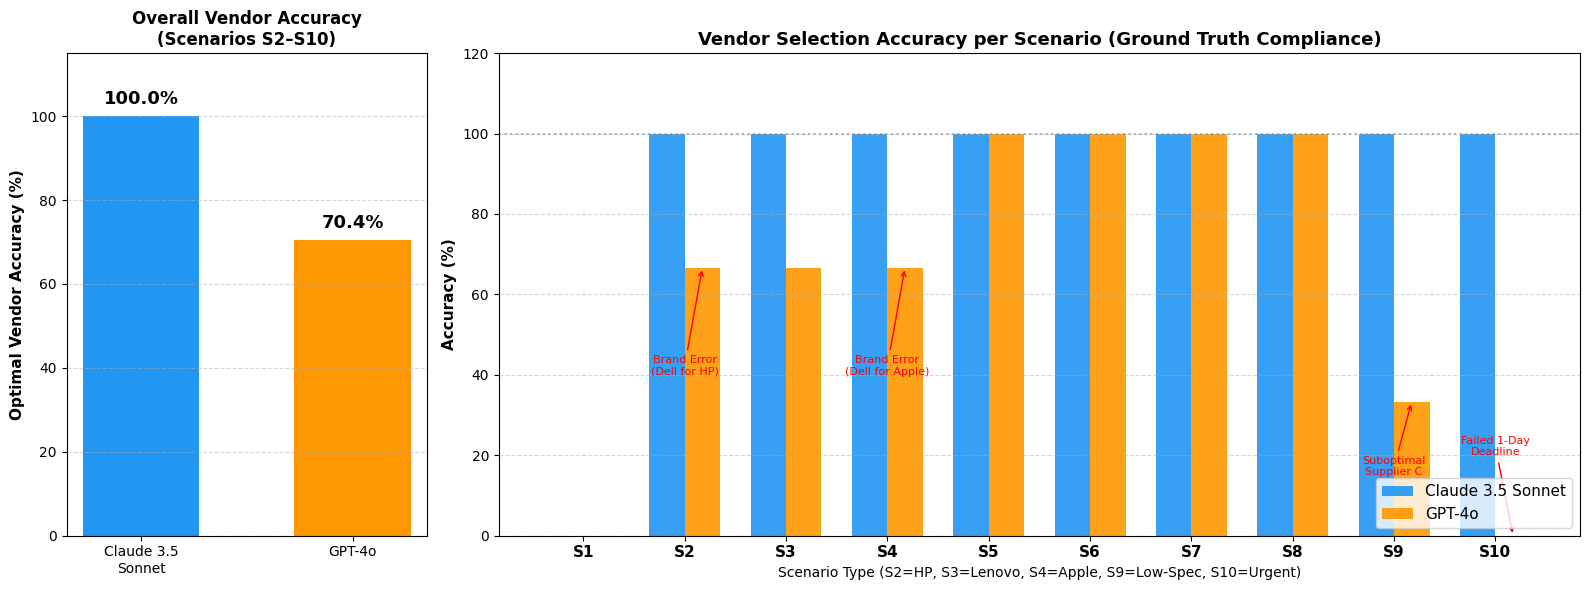

Saved: graph_vendor_accuracy_true.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── 1. Define Optimal Expected Vendor Ground Truth ────────────────────────────
# S1: Inventory match (N/A)
# S2: Supplier B (HP)
# S3: Supplier F (Lenovo Optimal MCDA)
# S4: Supplier D (Apple MacBook)
# S5: Supplier B (HP Gaming)
# S6: Supplier A or G (Dell - Rejection Test)
# S7: Supplier G (Triage candidate before Rejection)
# S8: Supplier E (Acer)
# S9: Supplier F (Lenovo Optimal MCDA)
# S10: Supplier G (Dell 1-day delivery for Urgent Deadline)

df = pd.read_csv('all_results.csv')

optimal_vendors = {
    'S1': ['N/A'],
    'S2': ['Supplier B'],
    'S3': ['Supplier F'],
    'S4': ['Supplier D'],
    'S5': ['Supplier B'],
    'S6': ['Supplier A', 'Supplier G'],
    'S7': ['Supplier G'],
    'S8': ['Supplier E'],
    'S9': ['Supplier F'],
    'S10': ['Supplier G']  # Only G satisfies 1-day urgent deadline
}

scenarios = [f'S{i}' for i in range(1, 11)]
claude_scores = []
openai_scores = []

for s in scenarios:
    s_df = df[df['Scenario'] == s]
    valid_v = optimal_vendors[s]

    c_correct = sum(s_df['Claude_Vendor'].isin(valid_v)) / len(s_df) * 100
    o_correct = sum(s_df['OpenAI_Vendor'].isin(valid_v)) / len(s_df) * 100

    claude_scores.append(c_correct)
    openai_scores.append(o_correct)

# Overall Procurement Vendor Accuracy (Scenarios S2-S10)
c_overall = np.mean(claude_scores[1:])
o_overall = np.mean(openai_scores[1:])

# ── 2. Plot Detailed Comparison Graph ─────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1, 3]})

# Subplot 1: Overall Average Bar Chart
bars = ax1.bar(['Claude 3.5\nSonnet', 'GPT-4o'], [c_overall, o_overall], color=['#2196F3', '#FF9800'], width=0.55)
ax1.set_ylim(0, 115)
ax1.set_ylabel('Optimal Vendor Accuracy (%)', fontsize=11, fontweight='bold')
ax1.set_title('Overall Vendor Accuracy\n(Scenarios S2–S10)', fontsize=12, fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for bar, val in zip(bars, [c_overall, o_overall]):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
             f'{val:.1f}%', ha='center', va='bottom', fontsize=13, fontweight='bold')

# Subplot 2: Breakdown by Scenario (S1-S10)
x = np.arange(len(scenarios))
w = 0.35

ax2.bar(x - w/2, claude_scores, w, label='Claude 3.5 Sonnet', color='#2196F3', alpha=0.9)
ax2.bar(x + w/2, openai_scores, w, label='GPT-4o', color='#FF9800', alpha=0.9)

ax2.set_xticks(x)
ax2.set_xticklabels(scenarios, fontsize=11, fontweight='bold')
ax2.set_ylim(0, 120)
ax2.set_ylabel('Accuracy (%)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Scenario Type (S2=HP, S3=Lenovo, S4=Apple, S9=Low-Spec, S10=Urgent)', fontsize=10)
ax2.set_title('Vendor Selection Accuracy per Scenario (Ground Truth Compliance)', fontsize=13, fontweight='bold')
ax2.axhline(100, color='gray', linestyle=':', alpha=0.6)
ax2.legend(fontsize=11, loc='lower right')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate specific drop points for GPT-4o
ax2.annotate('Brand Error\n(Dell for HP)', xy=(1 + w/2, 66.7), xytext=(1, 40),
             arrowprops=dict(arrowstyle='->', color='red'), fontsize=8, ha='center', color='red')
ax2.annotate('Brand Error\n(Dell for Apple)', xy=(3 + w/2, 66.7), xytext=(3, 40),
             arrowprops=dict(arrowstyle='->', color='red'), fontsize=8, ha='center', color='red')
ax2.annotate('Suboptimal\nSupplier C', xy=(8 + w/2, 33.3), xytext=(8, 15),
             arrowprops=dict(arrowstyle='->', color='red'), fontsize=8, ha='center', color='red')
ax2.annotate('Failed 1-Day\nDeadline', xy=(9 + w/2, 0), xytext=(9, 20),
             arrowprops=dict(arrowstyle='->', color='red'), fontsize=8, ha='center', color='red')

plt.tight_layout()
plt.savefig('graph_vendor_accuracy_true.png', dpi=300)
plt.show()
print("Saved: graph_vendor_accuracy_true.png")

## 12. Multi-Agent Performance Comparison
| Evaluation Metric | Version 1: Anthropic Claude | Version 2: OpenAI GPT-4o | Notes |
| :--- | :--- | :--- | :--- |
| **Decision Accuracy (Yes/No)** | | | Was the correct supplier chosen within budget? |
| **Quality of Decisions (1-5)** | | | Star rating on logical depth of choices. |
| **Execution Time (Seconds)** | | | Logged time in cells above. |
| **Consistency (Same/Different)** | | | Run both cells 3 times to check variation. |
| **Human Interventions needed (Qty)**| | | How many times did human verify/reject outputs. |
| **AI Explanation Clarity (1-5)** | | | Star rating on justifications provided. |